# Homework 4
Gabriel Almodovar

Student ID: 801296062


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import mean_squared_error, confusion_matrix

drive.mount('/content/drive')

Mounted at /content/drive


## Problem 1: Cancer classification

In [2]:
file_path = '/content/drive/My Drive/Courses/Intro-to-ML/Datasets/Cancer.csv'
cancer = pd.read_csv(file_path)
cancer.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
cancer = cancer.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
cancer = cancer.dropna()
cancer['diagnosis'] = cancer['diagnosis'].map({'M': 1, 'B': 0})

X = cancer.drop(columns=['diagnosis']).to_numpy(dtype=float)
Y = cancer['diagnosis'].to_numpy()

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
svm_linear = SVC(kernel='linear', C=1)
svm_rbf = SVC(kernel='rbf', C=1, gamma='scale')
svm_poly = SVC(kernel='poly', C=1, degree=3, coef0=1, gamma='scale')

svm_linear.fit(X_train, Y_train)
svm_rbf.fit(X_train, Y_train)
svm_poly.fit(X_train, Y_train)

prediction_linear = svm_linear.predict(X_test)
prediction_rbf = svm_rbf.predict(X_test)
prediction_poly = svm_poly.predict(X_test)

In [5]:
accuracy = [
    accuracy_score(Y_test, prediction_linear),
    accuracy_score(Y_test, prediction_rbf),
    accuracy_score(Y_test, prediction_poly),
]

precision = [
    precision_score(Y_test, prediction_linear, zero_division=0),
    precision_score(Y_test, prediction_rbf, zero_division=0),
    precision_score(Y_test, prediction_poly, zero_division=0),
]

recall = [
    recall_score(Y_test, prediction_linear, zero_division=0),
    recall_score(Y_test, prediction_rbf, zero_division=0),
    recall_score(Y_test, prediction_poly, zero_division=0),
]

cancer_results = pd.DataFrame({
    'Model': ['Linear SVM', 'RBF SVM', 'Polynomial SVM'],
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall
})

cancer_results

,Model,Accuracy,Precision,Recall
0,Linear SVM,0.964912,1.0,0.904762
1,RBF SVM,0.973684,1.0,0.928571
2,Polynomial SVM,0.982456,1.0,0.952381


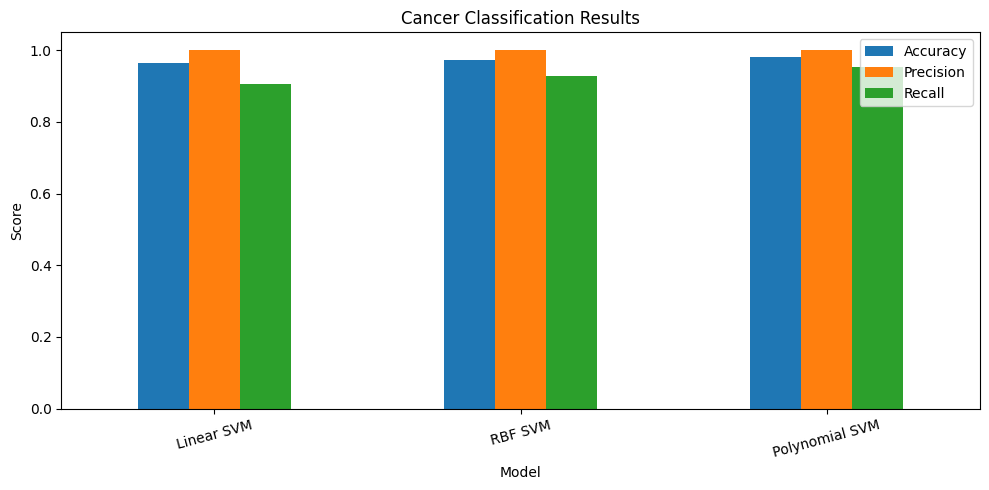

In [6]:
cancer_results.set_index('Model').plot.bar(figsize=(10, 5))
plt.xlabel('Model')
plt.ylabel('Score')
plt.title('Cancer Classification Results')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
hw3_comparison = pd.DataFrame({
    'Model': ['HW3 Logistic', 'HW3 Logistic with L2', 'HW4 Polynomial SVM'],
    'Accuracy': [0.9737, 0.9825, accuracy[2]],
    'Precision': [0.9756, 1.0000, precision[2]],
    'Recall': [0.9524, 0.9524, recall[2]]
})
hw3_comparison


,Model,Accuracy,Precision,Recall
0,HW3 Logistic,0.973700,0.9756,0.952400
1,HW3 Logistic with L2,0.982500,1.0000,0.952400
2,HW4 Polynomial SVM,0.982456,1.0000,0.952381


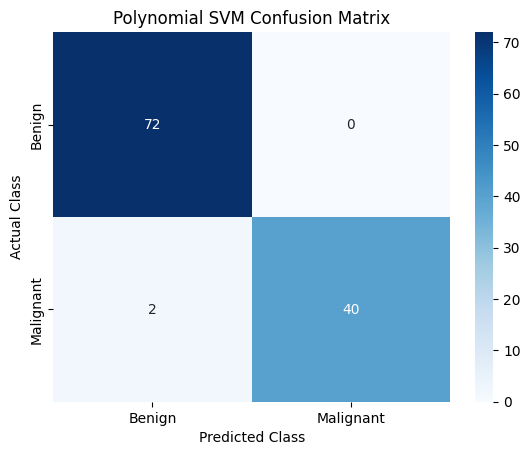

In [8]:
matrix = confusion_matrix(Y_test, prediction_poly)
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Polynomial SVM Confusion Matrix')
plt.show()


In [9]:
Y_margin = 2 * Y_train - 1

train_loss_linear = np.mean(np.maximum(0, 1 - Y_margin * svm_linear.decision_function(X_train)))
train_loss_rbf = np.mean(np.maximum(0, 1 - Y_margin * svm_rbf.decision_function(X_train)))
train_loss_poly = np.mean(np.maximum(0, 1 - Y_margin * svm_poly.decision_function(X_train)))

cancer_training_loss = pd.DataFrame({
    'Model': ['Linear SVM', 'RBF SVM', 'Polynomial SVM'],
    'Training Margin Loss': [train_loss_linear, train_loss_rbf, train_loss_poly]
})
cancer_training_loss


,Model,Training Margin Loss
0,Linear SVM,0.037240
1,RBF SVM,0.056451
2,Polynomial SVM,0.036710


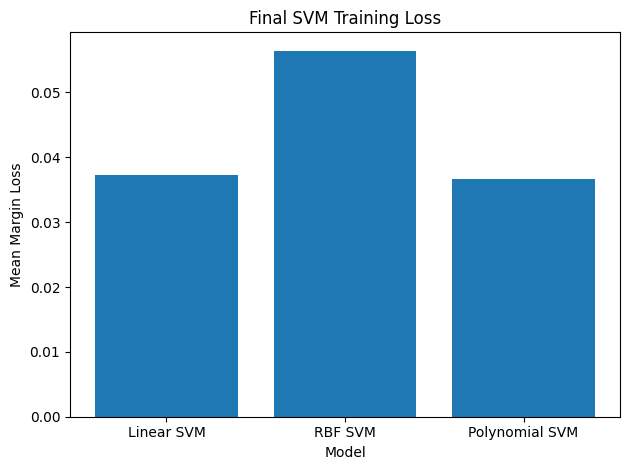

In [10]:
plt.bar(cancer_training_loss['Model'], cancer_training_loss['Training Margin Loss'])
plt.xlabel('Model')
plt.ylabel('Mean Margin Loss')
plt.title('Final SVM Training Loss')
plt.tight_layout()
plt.show()


## Problem 2: Housing price regression

In [11]:
file_path = '/content/drive/My Drive/Courses/Intro-to-ML/Datasets/Housing.csv'
housing = pd.read_csv(file_path)
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [12]:
features = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
            'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
            'parking', 'prefarea']

housing = housing[['price'] + features].copy()
housing = housing.replace({'yes': 1, 'no': 0})
housing = housing.dropna()

X = housing[features].to_numpy(dtype=float)
Y = housing['price'].to_numpy(dtype=float)

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

scaler_Y = StandardScaler()
Y_train_scaled = scaler_Y.fit_transform(Y_train.reshape(-1, 1)).ravel()

/tmp/ipykernel_1538/3298096133.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  housing = housing.replace({'yes': 1, 'no': 0})


In [13]:
svr_linear = SVR(kernel='linear', C=10, epsilon=0.1)
svr_rbf = SVR(kernel='rbf', C=10, epsilon=0.1, gamma='scale')
svr_poly = SVR(kernel='poly', C=10, epsilon=0.1, degree=2,
               coef0=1, gamma='scale')

svr_linear.fit(X_train_scaled, Y_train_scaled)
svr_rbf.fit(X_train_scaled, Y_train_scaled)
svr_poly.fit(X_train_scaled, Y_train_scaled)

prediction_linear = svr_linear.predict(X_test_scaled)
prediction_rbf = svr_rbf.predict(X_test_scaled)
prediction_poly = svr_poly.predict(X_test_scaled)

prediction_linear = scaler_Y.inverse_transform(prediction_linear.reshape(-1, 1)).ravel()
prediction_rbf = scaler_Y.inverse_transform(prediction_rbf.reshape(-1, 1)).ravel()
prediction_poly = scaler_Y.inverse_transform(prediction_poly.reshape(-1, 1)).ravel()

In [14]:
ridge = Ridge(alpha=1)
ridge.fit(X_train_scaled, Y_train)
prediction_ridge = ridge.predict(X_test_scaled)

In [15]:
train_prediction_linear_scaled = svr_linear.predict(X_train_scaled)
train_prediction_rbf_scaled = svr_rbf.predict(X_train_scaled)
train_prediction_poly_scaled = svr_poly.predict(X_train_scaled)

train_prediction_linear = scaler_Y.inverse_transform(train_prediction_linear_scaled.reshape(-1, 1)).ravel()
train_prediction_rbf = scaler_Y.inverse_transform(train_prediction_rbf_scaled.reshape(-1, 1)).ravel()
train_prediction_poly = scaler_Y.inverse_transform(train_prediction_poly_scaled.reshape(-1, 1)).ravel()
train_prediction_ridge = ridge.predict(X_train_scaled)

train_loss_linear = np.mean(np.square(train_prediction_linear - Y_train))
train_loss_rbf = np.mean(np.square(train_prediction_rbf - Y_train))
train_loss_poly = np.mean(np.square(train_prediction_poly - Y_train))
train_loss_ridge = np.mean(np.square(train_prediction_ridge - Y_train))

housing_training_loss = pd.DataFrame({
    'Model': ['Linear SVR', 'RBF SVR', 'Polynomial SVR', 'Ridge Regression'],
    'Training MSE': [train_loss_linear, train_loss_rbf, train_loss_poly, train_loss_ridge]
})
housing_training_loss


,Model,Training MSE
0,Linear SVR,1.018477e+12
1,RBF SVR,2.778425e+11
2,Polynomial SVR,7.680314e+11
3,Ridge Regression,9.924849e+11


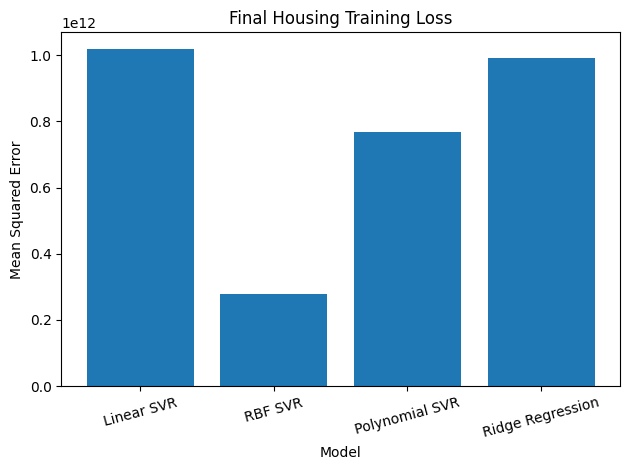

In [16]:
plt.bar(housing_training_loss['Model'], housing_training_loss['Training MSE'])
plt.xlabel('Model')
plt.ylabel('Mean Squared Error')
plt.title('Final Housing Training Loss')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [17]:
epsilon_loss_linear = np.mean(np.maximum(0, np.abs(Y_train_scaled - train_prediction_linear_scaled) - svr_linear.epsilon))
epsilon_loss_rbf = np.mean(np.maximum(0, np.abs(Y_train_scaled - train_prediction_rbf_scaled) - svr_rbf.epsilon))
epsilon_loss_poly = np.mean(np.maximum(0, np.abs(Y_train_scaled - train_prediction_poly_scaled) - svr_poly.epsilon))

svr_training_loss = pd.DataFrame({
    'Model': ['Linear SVR', 'RBF SVR', 'Polynomial SVR'],
    'Training Epsilon Loss': [epsilon_loss_linear, epsilon_loss_rbf, epsilon_loss_poly]
})
svr_training_loss


,Model,Training Epsilon Loss
0,Linear SVR,0.318686
1,RBF SVR,0.101252
2,Polynomial SVR,0.249334


In [18]:
mse = [
    mean_squared_error(Y_test, prediction_linear),
    mean_squared_error(Y_test, prediction_rbf),
    mean_squared_error(Y_test, prediction_poly),
    mean_squared_error(Y_test, prediction_ridge)
]

housing_results = pd.DataFrame({
    'Model': ['Linear SVR', 'RBF SVR', 'Polynomial SVR', 'Regularized Linear'],
    'Test MSE': mse
})
housing_results


,Model,Test MSE
0,Linear SVR,1.931053e+12
1,RBF SVR,1.905939e+12
2,Polynomial SVR,1.973463e+12
3,Regularized Linear,1.801383e+12


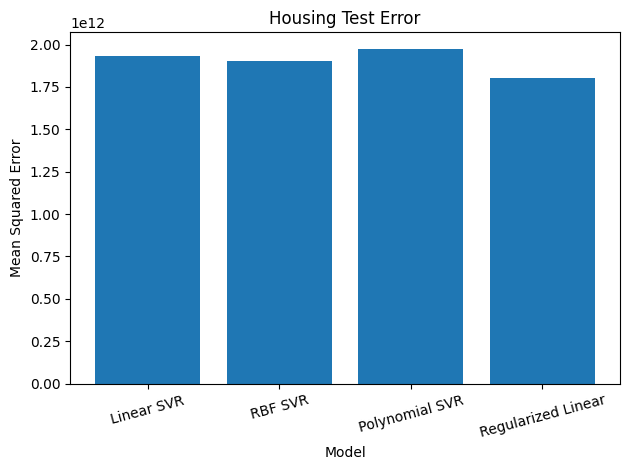

In [19]:
plt.bar(housing_results['Model'], housing_results['Test MSE'])
plt.xlabel('Model')
plt.ylabel('Mean Squared Error')
plt.title('Housing Test Error')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


The next plot orders test houses by actual price. Every prediction uses all 11 inputs; this is not a single-feature regression curve.

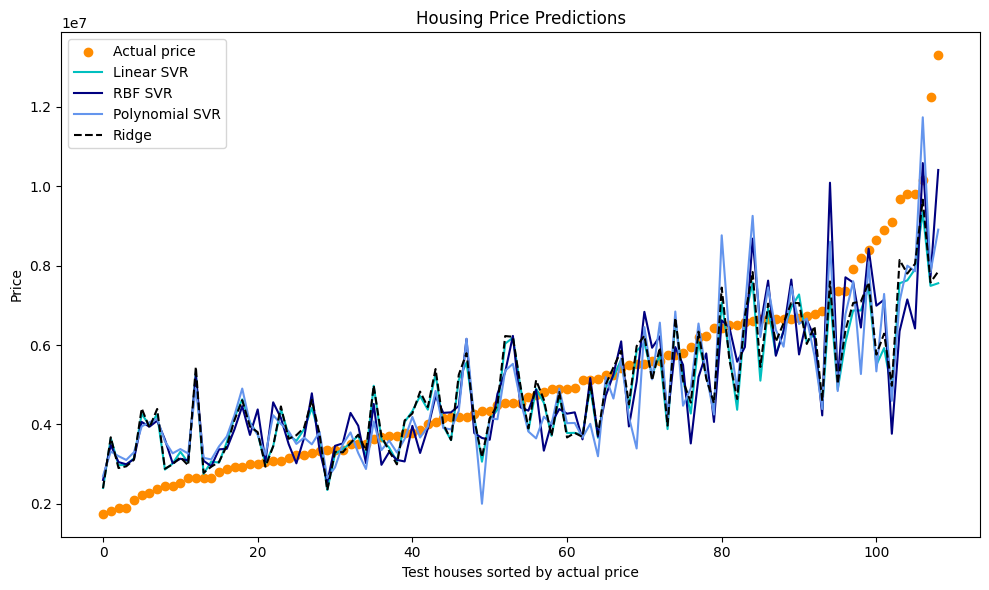

In [20]:
order = np.argsort(Y_test)
houses = np.arange(len(Y_test))

plt.figure(figsize=(10, 6))
plt.scatter(houses, Y_test[order], color='darkorange', label='Actual price')
plt.plot(houses, prediction_linear[order], color='c', label='Linear SVR')
plt.plot(houses, prediction_rbf[order], color='navy', label='RBF SVR')
plt.plot(houses, prediction_poly[order], color='cornflowerblue', label='Polynomial SVR')
plt.plot(houses, prediction_ridge[order], color='black', linestyle='--', label='Ridge')
plt.xlabel('Test houses sorted by actual price')
plt.ylabel('Price')
plt.title('Housing Price Predictions')
plt.legend()
plt.tight_layout()
plt.show()

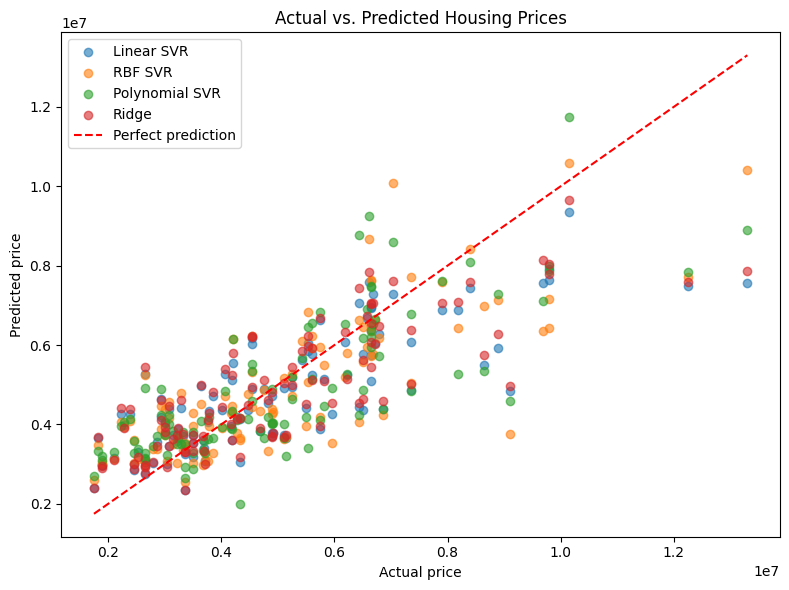

In [21]:
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, prediction_linear, alpha=0.6, label='Linear SVR')
plt.scatter(Y_test, prediction_rbf, alpha=0.6, label='RBF SVR')
plt.scatter(Y_test, prediction_poly, alpha=0.6, label='Polynomial SVR')
plt.scatter(Y_test, prediction_ridge, alpha=0.6, label='Ridge')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()],
         color='red', linestyle='--', label='Perfect prediction')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Actual vs. Predicted Housing Prices')
plt.legend()
plt.tight_layout()
plt.show()